# Churn Radar: building and testing the model

This notebook records how the churn model behind the app was built. It looks at the data, sets baselines, compares
candidate models with cross-validation, picks a threshold, tests once on held-out data, checks where the model fails,
and then saves it.

The goal is to rank customers each month by how likely they are to leave, so a retention team knows who to call first,
and to say why each customer is at risk. So the things that matter are ranking quality (ROC AUC, and precision and
recall on the call list) and explanations we can trust. Raw accuracy matters less.

A few rules apply throughout:
- The test set is split off first and isn't used again until section 8.
- Every choice (model, regularisation, threshold) is made with cross-validation on the training set.
- Reusable code lives in `src/`. Once something works here it moves there, and the notebook checks that the two agree.

In [1]:
import sys, datetime as dt
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.calibration import CalibrationDisplay
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, average_precision_score,
                             brier_score_loss, classification_report, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_val_predict,
                                     cross_validate, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))          # so `import src...` works from the notebook

pd.set_option("display.max_columns", 30)
SEED = 42
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


## 1. Load the data

The public [IBM Telco Customer Churn](https://github.com/IBM/telco-customer-churn-on-icp4d) dataset has one row per
customer: their services, account details, and whether they left in the last month (`Churn`).
It's downloaded once and cached in `data/raw/`, which git ignores.

In [2]:
DATA_URL = ("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/"
            "master/data/Telco-Customer-Churn.csv")

raw_path = ROOT / "data" / "raw" / "telco_churn.csv"
if not raw_path.exists():
    raw_path.parent.mkdir(parents=True, exist_ok=True)
    pd.read_csv(DATA_URL).to_csv(raw_path, index=False)

raw = pd.read_csv(raw_path)
print(raw.shape)
raw.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Data checks

Before modelling, check types, missing values, duplicates and the target balance.

In [3]:
print("numeric columns:", raw.select_dtypes("number").columns.tolist())
print("NaNs:", int(raw.isna().sum().sum()), "| duplicate IDs:", int(raw["customerID"].duplicated().sum()))
print("Churn:", raw["Churn"].value_counts(normalize=True).round(3).to_dict())

# Only 3 numeric columns were parsed. TotalCharges should be numeric too, why isn't it?
bad = pd.to_numeric(raw["TotalCharges"], errors="coerce").isna()
print(f"\nTotalCharges values that aren't numbers: {bad.sum()}  ->  {raw.loc[bad, 'TotalCharges'].unique().tolist()}")
print("Their tenure:", raw.loc[bad, "tenure"].unique().tolist())
print("SeniorCitizen values:", sorted(raw["SeniorCitizen"].unique().tolist()), "(every other flag is Yes/No)")

numeric columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges']
NaNs: 0 | duplicate IDs: 0
Churn: {'No': 0.735, 'Yes': 0.265}

TotalCharges values that aren't numbers: 11  ->  [' ']
Their tenure: [0]
SeniorCitizen values: [0, 1] (every other flag is Yes/No)


Three things to deal with:
- `TotalCharges` is text because 11 customers have a blank value. All of them have `tenure == 0`, so they're new
  and haven't been billed yet. A blank here means 0, not unknown.
- `SeniorCitizen` is coded 0/1 while every other flag is Yes/No. Recoding it means it's treated as a category like the rest.
- 26.5% of customers churned. That's imbalanced but not severely. Predicting "stays" for everyone would score 73.5%
  accuracy, so accuracy isn't a useful measure here.

Is `TotalCharges` just `tenure * MonthlyCharges`? If so it adds little new information.

In [4]:
num = raw.assign(TotalCharges=pd.to_numeric(raw["TotalCharges"], errors="coerce").fillna(0))
print("corr(TotalCharges, tenure * MonthlyCharges) =",
      round(np.corrcoef(num["TotalCharges"], num["tenure"] * num["MonthlyCharges"])[0, 1], 4))
num[["tenure", "MonthlyCharges", "TotalCharges"]].corr().round(2)

corr(TotalCharges, tenure * MonthlyCharges) = 0.9996


,tenure,MonthlyCharges,TotalCharges
tenure,1.00,0.25,0.83
MonthlyCharges,0.25,1.00,0.65
TotalCharges,0.83,0.65,1.00


Almost exactly. The three numeric columns are strongly related, which matters later: in a linear model, correlated
inputs share credit, so individual coefficients have to be read with care.

These fixes live in `clean()` in `src/features.py`, so the app cleans uploaded files the same way.

In [5]:
from src.features import ID_COL, TARGET, NUMERIC, CATEGORICAL, FEATURES, clean, prepare
from src.features import DATA_URL as SRC_DATA_URL

assert DATA_URL == SRC_DATA_URL

df = clean(raw)
df[TARGET] = (df[TARGET] == "Yes").astype(int)

assert df[NUMERIC].notna().all().all()
assert set(df["SeniorCitizen"]) == {"Yes", "No"}
assert (df.loc[df["tenure"] == 0, "TotalCharges"] == 0).all()
assert clean(df).equals(df)            # safe to run twice (the app may get already-clean files)
print(f"{len(df):,} rows, churn rate {df[TARGET].mean():.1%}")

7,043 rows, churn rate 26.5%


## 3. Explore

Which customers leave? The model's explanations should end up repeating these patterns.

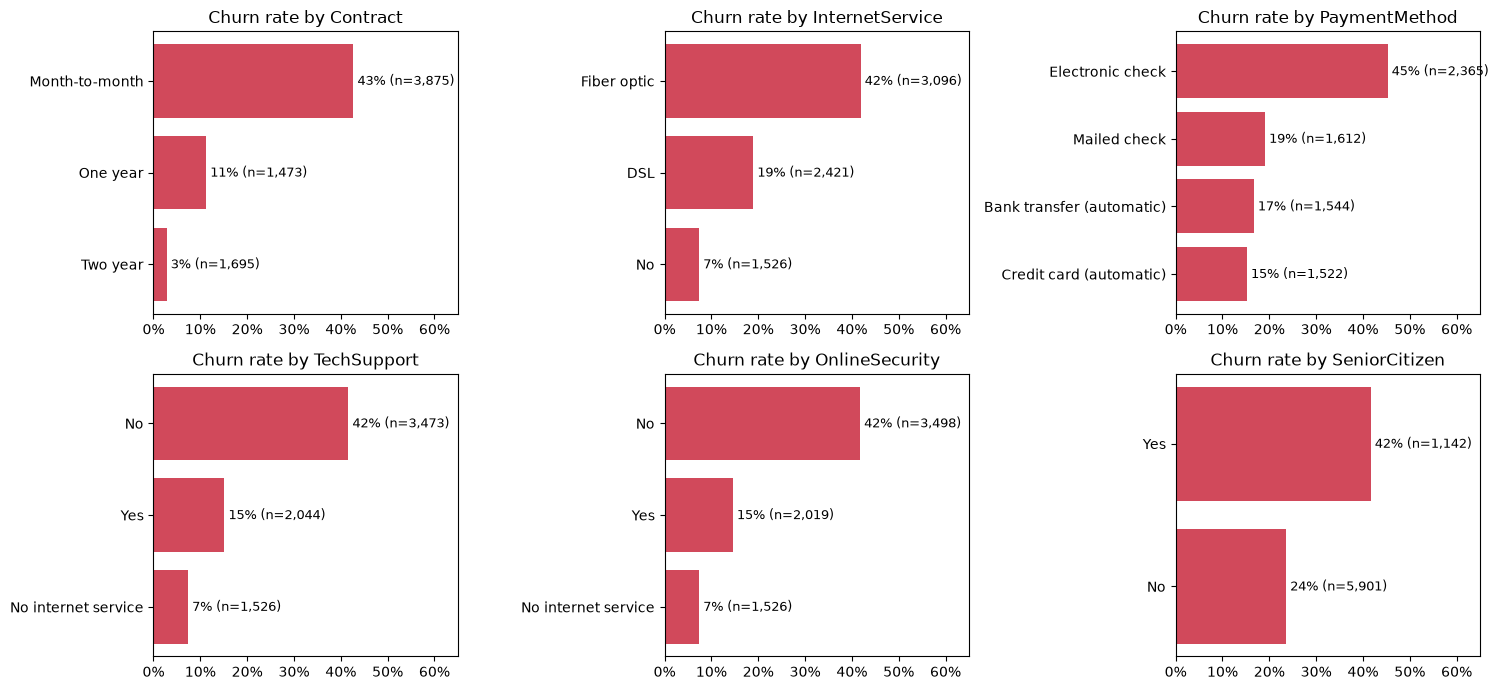

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.flat, ["Contract", "InternetService", "PaymentMethod",
                               "TechSupport", "OnlineSecurity", "SeniorCitizen"]):
    rate = df.groupby(col)[TARGET].agg(["mean", "size"]).sort_values("mean")
    ax.barh(rate.index, rate["mean"], color="#d1495b")
    for i, (r, n) in enumerate(zip(rate["mean"], rate["size"])):
        ax.text(r, i, f" {r:.0%} (n={n:,})", va="center", fontsize=9)
    ax.set_title(f"Churn rate by {col}"); ax.set_xlim(0, .65)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout()

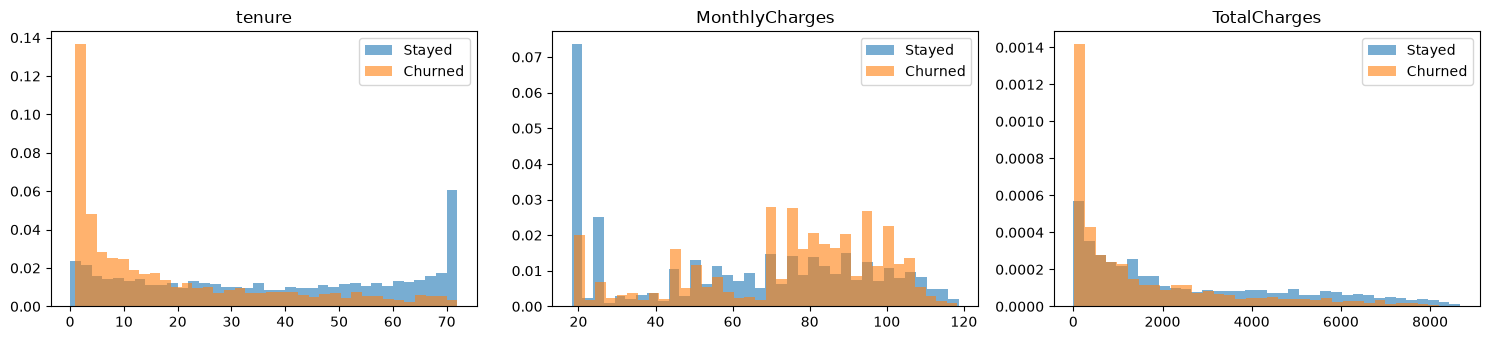

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col in zip(axes, NUMERIC):
    for label, grp in df.groupby(TARGET):
        ax.hist(grp[col], bins=36, alpha=.6, density=True, label="Churned" if label else "Stayed")
    ax.set_title(col); ax.legend()
plt.tight_layout()

Some patterns:
- Month-to-month contracts churn at about 43%, two-year contracts at about 3%.
- Fibre-optic internet, paying by electronic check, and having no tech support or online security all go with higher churn.
- Churn is concentrated in the first months. Long-standing customers rarely leave.
- Customers with high monthly bills churn more, but that probably reflects which services they have (fibre costs
  more) rather than price itself. Worth remembering when reading the coefficients.

## 4. Split off the test set

Hold out 20% of customers, stratified on churn so both sets have the same 26.5% rate.
Everything up to section 8 uses `X_train` only.

In [8]:
X, y = prepare(df), df[TARGET]
X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, df[ID_COL], test_size=0.2, stratify=y, random_state=SEED)

print(f"train {len(X_train):,} ({y_train.mean():.1%} churn)   test {len(X_test):,} ({y_test.mean():.1%} churn)")
assert not set(id_train) & set(id_test)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "brier": "neg_brier_score"}

train 5,634 (26.5% churn)   test 1,409 (26.5% churn)


## 5. Baselines

A model has to beat these to be worth using:
- Predict the overall churn rate for everyone. ROC AUC is 0.5 by definition.
- A single rule, "month-to-month contract means at risk". A manager might already do this without a model.

In [9]:
def cv_scores(estimator, name):
    r = cross_validate(estimator, X_train, y_train, cv=cv, scoring=SCORING)
    return {"model": name,
            "roc_auc": r["test_roc_auc"].mean(), "roc_auc_sd": r["test_roc_auc"].std(),
            "pr_auc": r["test_pr_auc"].mean(), "brier": -r["test_brier"].mean(),
            "fit_s": r["fit_time"].mean()}

results = [cv_scores(DummyClassifier(strategy="prior"), "Prior (no model)")]

rule = (X_train["Contract"] == "Month-to-month").astype(int)
results.append({"model": "Rule: month-to-month", "roc_auc": roc_auc_score(y_train, rule),
                "pr_auc": average_precision_score(y_train, rule)})
pd.DataFrame(results).set_index("model").round(3)

,roc_auc,roc_auc_sd,pr_auc,brier,fit_s
model,,,,,
Prior (no model),0.500,0.0,0.265,0.195,0.002
Rule: month-to-month,0.729,NaN,0.409,NaN,NaN


## 6. Candidate models

All models share one preprocessing step: scale the numeric columns and one-hot encode the categories, with
`handle_unknown="ignore"` so a category the model hasn't seen doesn't crash the app. Preprocessing is part of the
pipeline, so each CV fold fits the scaler on its own training part and nothing leaks.

The candidates:
- Logistic regression, with and without `class_weight="balanced"`. Its explanations are exact and simple.
- Random forest and gradient boosting. They can pick up interactions, but explaining their predictions needs
  approximations such as SHAP.

In [10]:
def make_prep():
    return ColumnTransformer([
        ("num", StandardScaler(), NUMERIC),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
    ])

candidates = {
    "Logistic regression (balanced)": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Logistic regression": LogisticRegression(max_iter=1000),
    "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                                            n_jobs=-1, random_state=SEED),
    "Gradient boosting": HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, random_state=SEED),
}
for name, clf in candidates.items():
    results.append(cv_scores(Pipeline([("prep", make_prep()), ("clf", clf)]), name))

leaderboard = pd.DataFrame(results).set_index("model").round(3)
leaderboard

,roc_auc,roc_auc_sd,pr_auc,brier,fit_s
model,,,,,
Prior (no model),0.500,0.000,0.265,0.195,0.002
Rule: month-to-month,0.729,NaN,0.409,NaN,NaN
Logistic regression (balanced),0.846,0.012,0.660,0.165,0.071
Logistic regression,0.846,0.013,0.661,0.135,0.064
Random forest,0.845,0.009,0.653,0.157,0.422
Gradient boosting,0.834,0.007,0.640,0.142,0.603


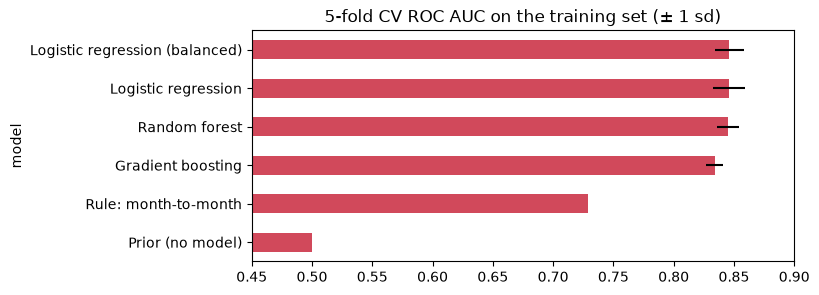

In [11]:
ax = leaderboard["roc_auc"].dropna().sort_values().plot.barh(
    xerr=leaderboard["roc_auc_sd"].dropna(), color="#d1495b", figsize=(7, 3))
ax.set_xlim(.45, .9); ax.set_title("5-fold CV ROC AUC on the training set (± 1 sd)");

All the models beat the single rule by a wide margin (about 0.85 against 0.73 AUC). Logistic regression, random
forest and gradient boosting are within one standard deviation of each other, so the tree models' extra complexity
doesn't buy anything here.

Balanced class weights give the same ranking (same AUC and PR AUC) but a worse Brier score. They push every
probability up, so the scores overstate the real chance of churning. Section 8 checks this on the test set.

I went with balanced logistic regression. It ranks as well as the others, its explanations are exact (section 10), and
the balanced weights put the useful thresholds in the middle of the app's 0 to 1 slider. The cost is that its outputs
are risk scores for ranking, not calibrated probabilities. That goes in the limits in section 12.

### Regularisation strength

In [12]:
lr_pipe = Pipeline([("prep", make_prep()),
                    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))])
grid = GridSearchCV(lr_pipe, {"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]}, cv=cv, scoring="roc_auc").fit(X_train, y_train)

c_scores = pd.Series(grid.cv_results_["mean_test_score"], index=grid.cv_results_["param_clf__C"].data, name="cv_roc_auc")
c_scores.round(4)

0.01     0.8440
0.03     0.8450
0.10     0.8455
0.30     0.8458
1.00     0.8460
3.00     0.8461
10.00    0.8462
Name: cv_roc_auc, dtype: float64

AUC moves by less than 0.003 across three orders of magnitude of `C`. With about 5,600 rows and 19 inputs the model
isn't overfitting, so the default `C=1.0` stays.

### Move the chosen pipeline into `src/`

The app builds its model with `build_pipeline()` from `src/features.py`. Check that it matches what was chosen here.

In [13]:
from src.features import build_pipeline

ours = {k: repr(v) for k, v in lr_pipe.get_params().items()}
shipped = build_pipeline().get_params()
diff = [k for k in ours if ours[k] != repr(shipped[k])]
assert not diff, diff
print("src.features.build_pipeline() matches the chosen model:",
      shipped["clf"], "| C =", shipped["clf__C"])

src.features.build_pipeline() matches the chosen model: LogisticRegression(class_weight='balanced', max_iter=1000) | C = 1.0


## 7. Choose the call-list threshold

The app puts everyone above a threshold on the list to call this month. The threshold is chosen from out-of-fold
predictions on the training set, which keeps the test set untouched.

What matters is how many people the team has to call and how many churners that reaches.

,share_called,precision,recall
threshold,,,
0.30,0.579,0.424,0.926
0.35,0.537,0.446,0.902
0.40,0.488,0.471,0.866
0.45,0.450,0.492,0.833
0.50,0.411,0.517,0.801
0.55,0.375,0.542,0.765
0.60,0.334,0.571,0.719
0.65,0.297,0.594,0.665
0.70,0.250,0.629,0.593


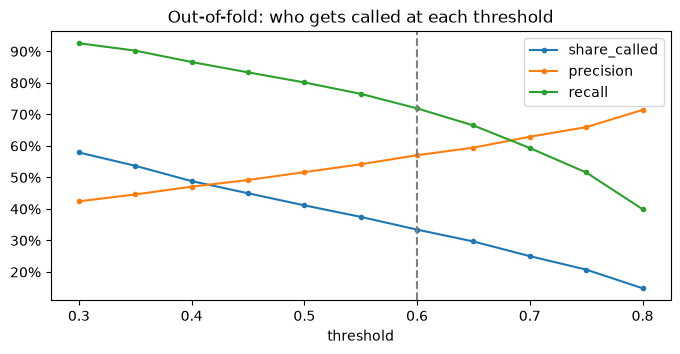

In [14]:
oof = cross_val_predict(build_pipeline(), X_train, y_train, cv=cv, method="predict_proba")[:, 1]

rows = []
for t in np.arange(0.3, 0.85, 0.05):
    flag = oof >= t
    rows.append({"threshold": round(t, 2), "share_called": flag.mean(),
                 "precision": precision_score(y_train, flag), "recall": recall_score(y_train, flag)})
thr = pd.DataFrame(rows).set_index("threshold")

ax = thr.plot(figsize=(8, 3.5), marker="o", ms=3)
ax.axvline(0.6, color="grey", ls="--"); ax.set_title("Out-of-fold: who gets called at each threshold")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
thr.round(3)

At 0.6 the list is about a third of customers. About 57% of the people called really are leaving, against 26.5%
when calling at random, and the list reaches about 72% of all churners. Lower thresholds catch more churners, but
the list grows quickly. 0.6 is the app's default, and the manager can move the slider to fit the team's capacity.

In [15]:
THRESHOLD = 0.6

## 8. Final test

Fit on the whole training set and score the held-out 20%, once. These are the numbers shown on the app's About page.

In [16]:
pipe = build_pipeline().fit(X_train, y_train)
proba = pipe.predict_proba(X_test)[:, 1]
pred = (proba >= THRESHOLD).astype(int)

metrics = {
    "roc_auc": roc_auc_score(y_test, proba),
    "pr_auc": average_precision_score(y_test, proba),
    "brier": brier_score_loss(y_test, proba),
    "precision": precision_score(y_test, pred),
    "recall": recall_score(y_test, pred),
    "threshold": THRESHOLD,
    "n_test": int(len(y_test)),
}
cv_auc = leaderboard.loc["Logistic regression (balanced)", "roc_auc"]
print({k: round(v, 3) for k, v in metrics.items()})
print(f"CV AUC {cv_auc:.3f}  vs  test AUC {metrics['roc_auc']:.3f}  (close = no sign of overfitting to the CV)")
print(classification_report(y_test, pred, target_names=["stay", "churn"]))

{'roc_auc': 0.842, 'pr_auc': 0.633, 'brier': 0.169, 'precision': 0.54, 'recall': 0.706, 'threshold': 0.6, 'n_test': 1409}
CV AUC 0.846  vs  test AUC 0.842  (close = no sign of overfitting to the CV)
              precision    recall  f1-score   support

        stay       0.88      0.78      0.83      1035
       churn       0.54      0.71      0.61       374

    accuracy                           0.76      1409
   macro avg       0.71      0.74      0.72      1409
weighted avg       0.79      0.76      0.77      1409



Calling the riskiest 30% reaches 65% of churners.


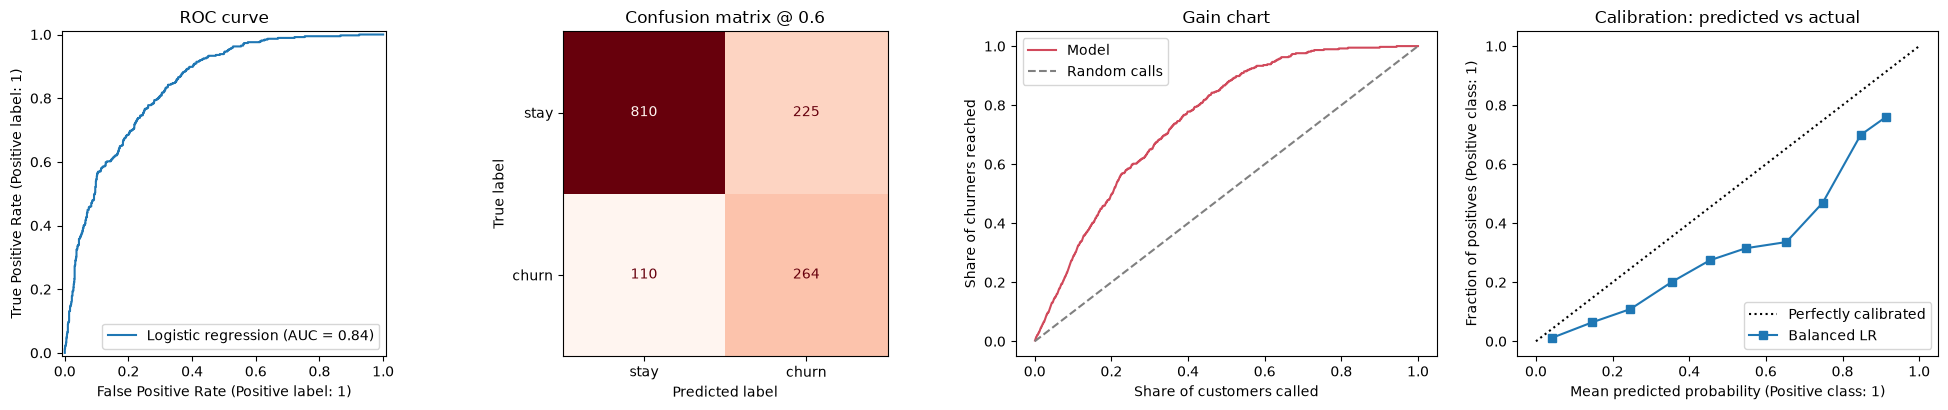

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
RocCurveDisplay.from_predictions(y_test, proba, ax=axes[0], name="Logistic regression")
axes[0].set_title("ROC curve")

ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["stay", "churn"], ax=axes[1],
                                        cmap="Reds", colorbar=False)
axes[1].set_title(f"Confusion matrix @ {THRESHOLD}")

# The manager's question: if we call the riskiest X%, what share of churners do we reach?
order = np.argsort(-proba)
captured = np.cumsum(y_test.to_numpy()[order]) / y_test.sum()
share = np.arange(1, len(order) + 1) / len(order)
axes[2].plot(share, captured, color="#d1495b", label="Model")
axes[2].plot([0, 1], [0, 1], "--", color="grey", label="Random calls")
axes[2].set_xlabel("Share of customers called"); axes[2].set_ylabel("Share of churners reached")
axes[2].set_title("Gain chart"); axes[2].legend()

CalibrationDisplay.from_predictions(y_test, proba, n_bins=10, ax=axes[3], name="Balanced LR")
axes[3].set_title("Calibration: predicted vs actual")
plt.tight_layout()

print(f"Calling the riskiest 30% reaches {captured[int(.3 * len(order))]:.0%} of churners.")

Test AUC is close to the CV estimate, so the model generalises as expected. The gain chart gives the figure to quote
to a manager: calling the riskiest 30% reaches about two thirds of churners.

The calibration curve sits below the diagonal, as section 6 suggested. Customers scored at 80% churn less often than
that. The scores are fine for ranking and comparing customers but shouldn't be read as probabilities.

## 9. Where does it fail?

Overall metrics can hide groups where the model does badly, so check ranking quality and call-list coverage by segment.

In [18]:
test_df = df.loc[X_test.index].assign(risk=proba, flagged=pred)

def by_segment(col):
    g = test_df.groupby(col)
    return pd.DataFrame({
        "n": g.size(),
        "churn_rate": g[TARGET].mean(),
        "share_flagged": g["flagged"].mean(),
        "roc_auc": g.apply(lambda d: roc_auc_score(d[TARGET], d["risk"]) if d[TARGET].nunique() == 2 else np.nan),
        "recall": g.apply(lambda d: d.loc[d[TARGET] == 1, "flagged"].mean()),
    })

pd.concat({c: by_segment(c) for c in ["Contract", "InternetService", "gender", "SeniorCitizen"]}).round(3)

n  churn_rate  share_flagged  roc_auc  \
Contract        Month-to-month   773       0.426          0.618    0.742   
                One year         300       0.120          0.037    0.743   
                Two year         336       0.027          0.000    0.759   
InternetService DSL              484       0.200          0.211    0.815   
                Fiber optic      613       0.411          0.631    0.781   
                No               312       0.080          0.000    0.893   
gender          Female           687       0.281          0.348    0.838   
                Male             722       0.251          0.346    0.847   
SeniorCitizen   No              1187       0.233          0.296    0.842   
                Yes              222       0.441          0.622    0.780   

                                recall  
Contract        Month-to-month   0.790  
                One year         0.111  
                Two year         0.000  
InternetService DSL              0.505  
                Fiber optic      0.853  
                No               0.000  
gender          Female           0.699  
                Male             0.713  
SeniorCitizen   No               0.663  
                Yes              0.827

- Within each contract type, AUC is lower than overall. Much of the model's power comes from telling contract types
  apart, and ranking customers within month-to-month is harder. Churners on one- and two-year contracts are rarely
  flagged, because they're rare and look like customers who stay.
- Men and women get similar performance and flag rates.
- Senior citizens are flagged much more often, partly because they do churn more. But their flag rate is higher than
  their churn rate, so seniors who would stay get called more than others. That needs a review before the score is
  used to decide who gets an offer.

Which churners does it miss most confidently, and who does it wrongly flag?

In [19]:
cols = [ID_COL, "risk", TARGET, "tenure", "Contract", "InternetService", "MonthlyCharges", "TechSupport", "PaymentMethod"]
print("Missed churners (low score, but left):")
display(test_df[test_df[TARGET] == 1].nsmallest(5, "risk")[cols])
print("False alarms (high score, but stayed):")
display(test_df[test_df[TARGET] == 0].nlargest(5, "risk")[cols])

Missed churners (low score, but left):


,customerID,risk,Churn,tenure,Contract,InternetService,MonthlyCharges,TechSupport,PaymentMethod
4386,3400-ESFUW,0.016601,1,55,Two year,DSL,57.55,Yes,Bank transfer (automatic)
4513,8580-QVLOC,0.029178,1,72,Two year,DSL,92.45,Yes,Credit card (automatic)
2894,8869-TORSS,0.074380,1,48,One year,DSL,60.35,Yes,Credit card (automatic)
5086,3705-PSNGL,0.086728,1,45,One year,No,20.40,No internet service,Electronic check
3834,2325-ZUSFD,0.111929,1,57,One year,DSL,70.10,No,Bank transfer (automatic)


False alarms (high score, but stayed):


,customerID,risk,Churn,tenure,Contract,InternetService,MonthlyCharges,TechSupport,PaymentMethod
3346,2545-EBUPK,0.920278,0,2,Month-to-month,Fiber optic,84.05,No,Electronic check
4039,8161-QYMTT,0.918038,0,7,Month-to-month,Fiber optic,94.10,No,Electronic check
935,6630-UJZMY,0.915989,0,4,Month-to-month,Fiber optic,83.25,No,Electronic check
5019,3320-VEOYC,0.911240,0,14,Month-to-month,Fiber optic,95.60,No,Electronic check
352,4115-NZRKS,0.906635,0,7,Month-to-month,Fiber optic,89.15,No,Electronic check


The missed churners look like loyal customers on paper, with long tenure and long contracts. Nothing in this data
says they're about to leave. The false alarms look like typical churners: new, month-to-month, fibre, paying by
electronic check. Both are limits of the available features, and more tuning won't fix them. It would take other data,
such as support tickets or recent complaints.

## 10. Explain each prediction

In a logistic regression, each feature's effect on the log-odds is exactly `coef * (value - training average)`.
`contributions()` in `src/model.py` computes this and adds the one-hot columns back up to the original feature, so
the app can say "Contract: Month-to-month" rather than `cat__Contract_Month-to-month`.

The baseline (the average transformed training row) is saved with the model, so the app compares each customer
against the same average customer.

In [20]:
from src import model as m

baseline = pipe.named_steps["prep"].transform(X_train).mean(axis=0)

bundle = {
    "pipeline": pipe,
    "baseline": baseline,
    "meta": {
        "version": "churn_v1",
        "trained_on": dt.date.today().isoformat(),
        "sklearn": sklearn.__version__,
        "data_url": "https://github.com/IBM/telco-customer-churn-on-icp4d",
        "n_rows": int(len(df)),
        "metrics": metrics,
        # Held-out predictions + CV leaderboard, so the About page can chart them (src/evaluation.py).
        "evaluation": {
            "test": (test_df[["Contract", "InternetService", "gender", "SeniorCitizen", "tenure"]]
                     .assign(churn=y_test.to_numpy(), risk=proba).to_dict("list")),
            "cv": leaderboard.reset_index()[["model", "roc_auc", "roc_auc_sd", "pr_auc"]].to_dict("records"),
            "chosen": "Logistic regression (balanced)",
        },
    },
}

contrib = m.contributions(bundle, test_df)

# Test: baseline log-odds + contributions must reproduce the model's own log-odds, for every customer.
clf = pipe.named_steps["clf"]
recon = clf.intercept_[0] + baseline @ clf.coef_[0] + contrib.sum(axis=1)
assert np.allclose(recon, pipe.decision_function(X_test)), "explanations don't add up"
assert list(contrib.columns.sort_values()) == sorted(FEATURES)
print("Explanations add up exactly for all", len(contrib), "test customers.")

for i, row in test_df.nlargest(3, "risk").iterrows():
    print(f"{row[ID_COL]}  risk {row['risk']:.0%}  ->  " + " | ".join(m.top_reasons(bundle, row, contrib.loc[i])))

Explanations add up exactly for all 1409 test customers.
5178-LMXOP  risk 94%  ->  Months as a customer: 1 | Internet service: Fiber optic | Contract: Month-to-month
0295-PPHDO  risk 93%  ->  Months as a customer: 1 | Internet service: Fiber optic | Contract: Month-to-month
6861-XWTWQ  risk 93%  ->  Months as a customer: 7 | Internet service: Fiber optic | Contract: Month-to-month


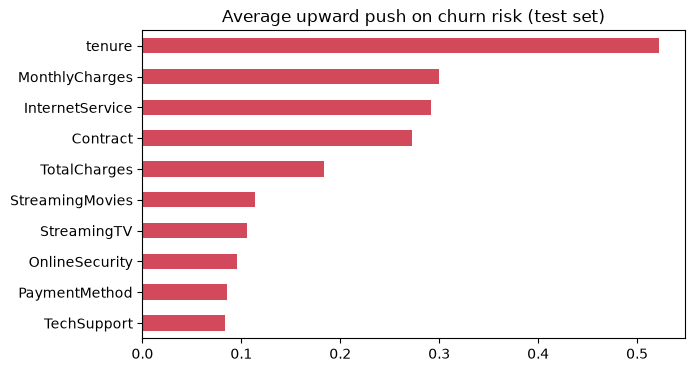

In [21]:
(contrib.clip(lower=0).mean().sort_values().tail(10)
   .plot.barh(color="#d1495b", figsize=(7, 4), title="Average upward push on churn risk (test set)"));

The top drivers (tenure, contract, fibre, payment method) match what showed up in section 3, so the explanations
should make sense to someone who knows the business.

### Which offers can the what-if include?

The app lets a manager try an offer and see how the score changes. That only makes sense for inputs whose
coefficient means what it seems to.

In [22]:
coefs = pd.Series(clf.coef_[0], pipe.named_steps["prep"].get_feature_names_out())
coefs.loc[["num__MonthlyCharges", "cat__Contract_Two year", "cat__TechSupport_Yes",
           "cat__OnlineSecurity_Yes", "cat__PaymentMethod_Credit card (automatic)"]].round(2)

num__MonthlyCharges                          -0.68
cat__Contract_Two year                       -0.77
cat__TechSupport_Yes                         -0.07
cat__OnlineSecurity_Yes                      -0.11
cat__PaymentMethod_Credit card (automatic)   -0.16
dtype: float64

`MonthlyCharges` has a negative coefficient, even though customers with high bills churn more in the raw data
(section 3). Once the services are in the model, a bigger bill mostly means more services, and those are already
counted, so the coefficient doesn't measure price. The model can't say what a discount would do, so the app doesn't
offer one. It offers contract length, tech support, online security and automatic payment instead.

## 11. Save, reload and test what the app runs

- `models/churn_v1.joblib` holds the pipeline, the baseline and metadata (version, date, metrics, test predictions)
  used on the About page.
- `data/sample.csv` holds 300 test-set customers without the `Churn` column, in the raw format a manager would upload.
  It's what the "Try with sample data" button loads. Using test-set customers means the demo never scores people the
  model was trained on.

In [23]:
m.MODEL_PATH.parent.mkdir(exist_ok=True)
joblib.dump(bundle, m.MODEL_PATH, compress=3)

sample = raw.set_index(ID_COL).loc[id_test].reset_index().drop(columns=[TARGET]).sample(300, random_state=7)
sample.to_csv(m.SAMPLE_PATH, index=False)

print(m.MODEL_PATH.relative_to(ROOT), f"{m.MODEL_PATH.stat().st_size / 1024:.0f} KB")
print(m.SAMPLE_PATH.relative_to(ROOT), sample.shape)

models/churn_v1.joblib 20 KB
data/sample.csv (300, 20)


Reload from disk the same way the app does, and run the checks the app relies on.

In [24]:
from src.features import validate

loaded = m.load_model()
s = pd.read_csv(m.SAMPLE_PATH)

# 1. The saved model gives the same scores as the one in memory.
assert np.allclose(m.predict_risk(loaded, test_df), proba)

# 2. The sample file is valid and scores cleanly: probabilities in (0, 1), no NaNs.
assert validate(s) == [], validate(s)
s["risk"] = m.predict_risk(loaded, s)
assert s["risk"].between(0, 1).all() and s["risk"].notna().all()

# 3. Order doesn't matter: each customer is scored independently.
shuffled = s.sample(frac=1, random_state=0)
assert np.allclose(m.predict_risk(loaded, shuffled), shuffled["risk"])

# 4. Raw and cleaned input give the same scores (the app may get either).
assert np.allclose(m.predict_risk(loaded, clean(s)), s["risk"])

# 5. A brand-new customer with a blank TotalCharges is scored, not crashed.
new = s.head(1).assign(tenure=0, TotalCharges=" ")
assert validate(new) == [] and 0 < m.predict_risk(loaded, new)[0] < 1

# 6. A category the model never saw is ignored, not a crash.
odd = s.head(1).assign(PaymentMethod="Crypto")
assert 0 < m.predict_risk(loaded, odd)[0] < 1

# 7. The About page's charts (src/evaluation.py) reproduce this notebook's test numbers.
from src import evaluation as ev
t = ev.test_frame(loaded)
assert np.allclose(t["risk"], proba)
row = ev.threshold_table(t["churn"], t["risk"], [THRESHOLD]).iloc[0]
assert np.isclose(row["precision"], metrics["precision"]) and np.isclose(row["recall"], metrics["recall"])
assert np.isclose(ev.gain_curve(t["churn"], t["risk"]).set_index("share_called").loc[0.3, "model"],
                  captured[int(.3 * len(order)) - 1], atol=0.01)
seg = ev.segment_table(t, "Contract", THRESHOLD).set_index("segment")
assert np.allclose(seg["share_flagged"], by_segment("Contract")["share_flagged"])

# 8. Bad uploads get a helpful message instead of a stack trace.
print(validate(s.drop(columns=["Contract", "tenure"])))
print(validate(s.head(3).assign(tenure="ten")))
print(validate(s.iloc[0:0]))

print("\nAll checks passed.")

['Missing columns: tenure, Contract']
["Column 'tenure' must be numeric (3 bad values)."]
['The file has no rows.']

All checks passed.


In [25]:
c = m.contributions(loaded, s)
s["top_reason"] = [m.top_reasons(loaded, s.loc[i], c.loc[i], 1)[0] for i in s.index]
s.sort_values("risk", ascending=False)[["customerID", "risk", "top_reason", "Contract", "tenure", "MonthlyCharges"]].head(10)

,customerID,risk,top_reason,Contract,tenure,MonthlyCharges
161,1400-MMYXY,0.920128,Months as a customer: 3,Month-to-month,3,105.90
56,4750-ZRXIU,0.915064,Months as a customer: 4,Month-to-month,4,84.60
69,2034-GDRCN,0.903798,Months as a customer: 2,Month-to-month,2,90.40
115,4587-VVTOX,0.898253,Months as a customer: 6,Month-to-month,6,105.30
105,6969-MVBAI,0.896109,Months as a customer: 9,Month-to-month,9,90.10
155,2077-MPJQO,0.887194,Months as a customer: 7,Month-to-month,7,75.40
284,6979-ZNSFF,0.885153,Months as a customer: 8,Month-to-month,8,87.05
37,2027-FECZV,0.883829,Months as a customer: 12,Month-to-month,12,106.70
79,7817-BOQPW,0.882188,Months as a customer: 2,Month-to-month,2,75.55
17,2609-IAICY,0.881347,Months as a customer: 1,Month-to-month,1,77.15


In [26]:
# What-if: offer the riskiest customer a two-year contract plus free tech support.
top = s.nlargest(1, "risk")
offer = top.assign(Contract="Two year", TechSupport="Yes")
after = m.predict_risk(loaded, offer)[0]
assert after < top["risk"].iloc[0]
print(f"Risk now {top['risk'].iloc[0]:.0%}  ->  with offer {after:.0%}")

Risk now 92%  ->  with offer 68%


## 12. Summary

| | |
|---|---|
| Model | Logistic regression (`class_weight="balanced"`, `C=1`) on scaled numeric columns and one-hot categories |
| Why this one | Ranks as well as random forest and boosting in CV, and its explanations are exact |
| Test ROC AUC | 0.84 (CV 0.85), against 0.73 for the month-to-month rule |
| At threshold 0.6 | 54% of the call list really churns (26.5% at random), and it reaches 71% of churners |
| Gain | Calling the riskiest 30% reaches 65% of churners |

Known limits, also listed on the app's About page:
- Scores rank well but aren't calibrated probabilities. The balanced weights push them up (section 8).
- They show associations, not causes. The what-if shows how the model responds, not how a customer will.
- There's no price what-if, because the bill can't be separated from the services it pays for (section 10).
- The model is weaker at ranking customers within one contract type, and mostly misses churners on longer contracts (section 9).
- Senior citizens are flagged above their real churn rate. Review this before scores decide who gets offers.
- The data is fictional and a single snapshot. Retrain on real data before making real decisions.

Deployment steps are in [`README.md`](README.md).